# RL Training on SupplyChainEnv

Trains a PPO agent (via [Stable-Baselines3](https://stable-baselines3.readthedocs.io/),
an optional `rl` dependency) to control a retailer's ordering decisions in a
2-echelon `Supplier -> Store` chain facing **seasonal** demand, and compares it
against a heuristic baseline from `chainsim.ai.baselines`.

The baseline is a classic order-up-to-`S` policy tuned from the demand's
long-run average — it can't see or react to *where in the season* we
currently are. PPO's observation includes a rolling window of recent demand,
so it has the information needed to raise its order quantity ahead of a
seasonal peak and lower it in a trough — something no single fixed `S` can
do. That's the specific, honest mechanism behind any advantage PPO shows
below, not "RL is generally smarter."


In [1]:
import time

import gymnasium as gym
import matplotlib.pyplot as plt
from stable_baselines3 import PPO

from chainsim.ai.baselines import OrderUpToAgent, RandomAgent, evaluate_agent
from chainsim.ai.gym_env import SupplyChainEnv
from chainsim.core import (
    DEFAULT_SKU,
    Retailer,
    SeasonalDemand,
    Supplier,
    SupplyChainNetwork,
    TransportLink,
)

SEED = 0
DEMAND_BASE, DEMAND_AMPLITUDE, DEMAND_PERIOD, DEMAND_NOISE = 20.0, 10.0, 13, 1.5
LEAD_TIME = 2
N_PERIODS = 52
MAX_ORDER = 150.0

## Build the environment

In [2]:
def build_network() -> SupplyChainNetwork:
    net = SupplyChainNetwork()
    # Ample, cheap upstream source: this notebook is about the Store's ordering
    # policy, not Supplier-side warehousing economics (see examples/02).
    net.add_node(
        Supplier(id="Supplier", holding_cost=0.05, initial_inventory={DEFAULT_SKU: 100_000})
    )
    net.add_node(
        Retailer(
            id="Store",
            holding_cost=1.0,
            backlog_cost=5.0,
            initial_inventory={DEFAULT_SKU: 40},
        )
    )
    net.add_edge(TransportLink(source="Supplier", destination="Store", lead_time=LEAD_TIME))
    return net


def make_env(n_periods: int = N_PERIODS) -> SupplyChainEnv:
    return SupplyChainEnv(
        network=build_network(),
        demand={
            "Store": SeasonalDemand(
                base=DEMAND_BASE,
                amplitude=DEMAND_AMPLITUDE,
                period_length=DEMAND_PERIOD,
                noise_std=DEMAND_NOISE,
            )
        },
        policies={},  # Supplier has no policy either: it just draws down its stock
        controlled_nodes="Store",
        max_order=MAX_ORDER,
        n_periods=n_periods,
        cost_weights={"holding": 1.0, "backlog": 1.0},
        demand_history_window=8,
    )


env = make_env()
print("action_space:", env.action_space)
print("observation_space:", env.observation_space)

action_space: Box(0.0, 150.0, (1,), float32)
observation_space: Box(-15000.0, 15000.0, (13,), float32)


## Heuristic baselines

`OrderUpToAgent` here uses `S = DEMAND_BASE * (LEAD_TIME + 1)` — the standard
order-up-to formula, but computed from the demand's long-run *average* only
(no seasonal awareness, and no safety stock beyond covering the pipeline).
`RandomAgent` is a sanity-check lower bound.


In [3]:
baseline_S = DEMAND_BASE * (LEAD_TIME + 1)
baseline_agent = OrderUpToAgent(env, S=baseline_S)
random_agent = RandomAgent(env)

baseline_result = evaluate_agent(env, baseline_agent, n_episodes=30, seed=100)
random_result = evaluate_agent(env, random_agent, n_episodes=30, seed=100)

print(
    f"OrderUpTo(S={baseline_S:.0f}) mean episode reward: {baseline_result['mean_reward']:.1f}"
    f" (+/- {baseline_result['std_reward']:.1f})"
)
print(
    f"Random               mean episode reward: {random_result['mean_reward']:.1f}"
    f" (+/- {random_result['std_reward']:.1f})"
)

OrderUpTo(S=60) mean episode reward: -2841.0 (+/- 107.6)
Random               mean episode reward: -67908.5 (+/- 9433.0)


## Train PPO

Continuous action spaces train much better when normalized to `[-1, 1]`
(Stable-Baselines3's own recommendation) rather than raw order-quantity
units, so we wrap the env with `gymnasium.wrappers.RescaleAction`; the
wrapper handles rescaling transparently, `SupplyChainEnv` itself is
unchanged.


In [4]:
train_env = gym.wrappers.RescaleAction(make_env(), min_action=-1, max_action=1)

model = PPO(
    "MlpPolicy",
    train_env,
    seed=SEED,
    n_steps=512,
    batch_size=64,
    learning_rate=3e-4,
    gamma=0.995,
    verbose=0,
)

t0 = time.time()
model.learn(total_timesteps=150_000)
print(f"Trained in {time.time() - t0:.0f}s")

Trained in 48s


## Evaluate: PPO vs. baseline vs. random

In [5]:
eval_env = gym.wrappers.RescaleAction(make_env(), min_action=-1, max_action=1)
ppo_result = evaluate_agent(eval_env, model, n_episodes=30, seed=100)

print(f"{'agent':<22}{'mean_reward':>14}{'std_reward':>14}")
for name, result in (
    ("PPO", ppo_result),
    (f"OrderUpTo(S={baseline_S:.0f})", baseline_result),
    ("Random", random_result),
):
    print(f"{name:<22}{result['mean_reward']:>14.1f}{result['std_reward']:>14.1f}")

baseline_cost = -baseline_result["mean_reward"]
ppo_cost = -ppo_result["mean_reward"]
cost_reduction = (baseline_cost - ppo_cost) / baseline_cost
print(f"\nPPO reduces average cost by {cost_reduction:.1%} versus the static baseline.")
assert ppo_result["mean_reward"] > baseline_result["mean_reward"], "PPO did not beat the baseline"

agent                    mean_reward    std_reward
PPO                           -954.3          83.4
OrderUpTo(S=60)              -2841.0         107.6
Random                      -67908.5        9433.0

PPO reduces average cost by 66.4% versus the static baseline.


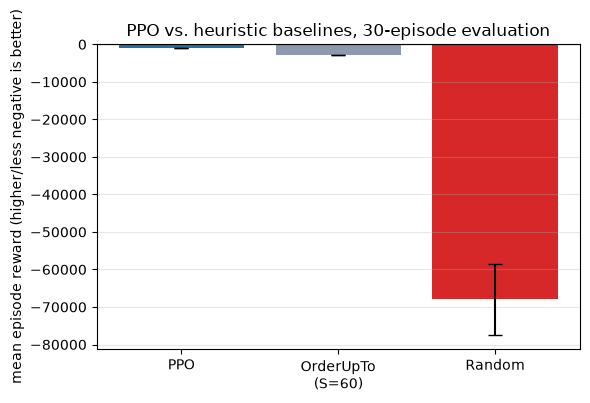

In [6]:
fig, ax = plt.subplots(figsize=(6, 4))
labels = ["PPO", f"OrderUpTo\n(S={baseline_S:.0f})", "Random"]
means = [ppo_result["mean_reward"], baseline_result["mean_reward"], random_result["mean_reward"]]
stds = [ppo_result["std_reward"], baseline_result["std_reward"], random_result["std_reward"]]
colors = ["#2a6f97", "#8d99ae", "#d62828"]
ax.bar(labels, means, yerr=stds, color=colors, capsize=5)
ax.set_ylabel("mean episode reward (higher/less negative is better)")
ax.set_title("PPO vs. heuristic baselines, 30-episode evaluation")
ax.axhline(0, color="black", linewidth=0.8)
ax.grid(axis="y", alpha=0.3)
fig.tight_layout()
fig.savefig("03_rl_training_comparison.png", dpi=150)
plt.show()

## Why: one episode, side by side

Same demand realization for both agents (same eval seed). Both policies
swing between near-zero and a peak stock — a normal order-up-to review
oscillation given the 2-period lead time — but PPO's peaks land closer to
the demand cycle's actual rises, since its observation includes recent
demand and the baseline's fixed `S` has no way to use that information at
all.


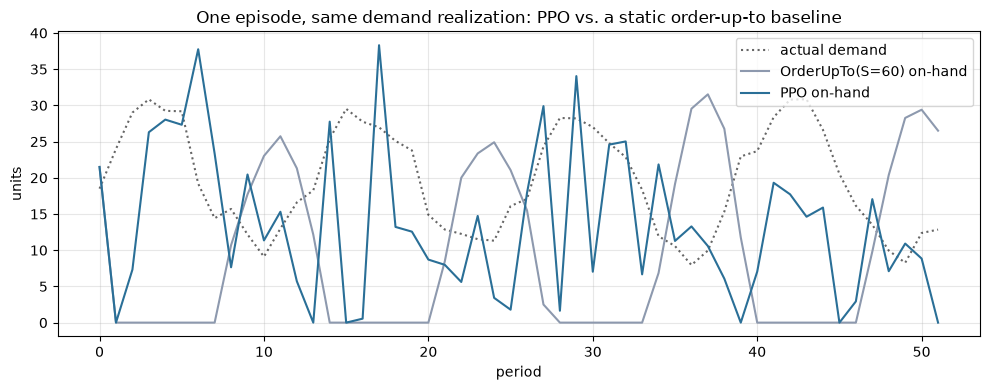

In [7]:
def run_episode(agent_env, agent, seed):
    obs, _ = agent_env.reset(seed=seed)
    terminated = truncated = False
    while not (terminated or truncated):
        if hasattr(agent, "predict"):
            action, _ = agent.predict(obs, deterministic=True)
        else:
            action = agent.act(obs)
        obs, _reward, terminated, truncated, _info = agent_env.step(action)
    return agent_env.unwrapped.engine.finish()


baseline_env = make_env()
ppo_env = gym.wrappers.RescaleAction(make_env(), min_action=-1, max_action=1)

baseline_history = run_episode(baseline_env, OrderUpToAgent(baseline_env, S=baseline_S), seed=999)
ppo_history = run_episode(ppo_env, model, seed=999)

baseline_store = baseline_history[baseline_history.node_id == "Store"]
ppo_store = ppo_history[ppo_history.node_id == "Store"]

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(
    baseline_store["period"],
    baseline_store["external_demand"],
    color="black",
    linestyle=":",
    label="actual demand",
    alpha=0.6,
)
ax.plot(
    baseline_store["period"],
    baseline_store["on_hand"],
    color="#8d99ae",
    label=f"OrderUpTo(S={baseline_S:.0f}) on-hand",
)
ax.plot(ppo_store["period"], ppo_store["on_hand"], color="#2a6f97", label="PPO on-hand")
ax.set_xlabel("period")
ax.set_ylabel("units")
ax.set_title("One episode, same demand realization: PPO vs. a static order-up-to baseline")
ax.legend()
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig("03_rl_training_trajectory.png", dpi=150)
plt.show()

## Takeaways

- PPO beat the static baseline by exploiting information the baseline
  structurally can't use: recent demand history, which lets it anticipate
  the seasonal cycle instead of carrying one constant buffer year-round.
- This isn't "RL beats classical inventory theory" in general — see
  `examples/02_custom_policy.py`, where a hand-designed adaptive heuristic
  *lost* to a well-calibrated static baseline. The lesson both notebooks
  point to is the same one the newsvendor/base-stock formulas already
  teach: a policy is only as good as the information and safety margin it's
  built on. RL is one way to *learn* a mapping from observed information to
  a decision when the right functional form isn't obvious upfront; it isn't
  a free win over a policy that already uses the same information well.
- `chainsim.ai.baselines.evaluate_agent` accepts anything with `.act(obs)`
  or Stable-Baselines3's `.predict(obs)` — the exact same harness evaluated
  both the heuristic and the learned policy above.
